# Pima Indians Diabetes Prediction using Logistic Regression
**Student Name:** Rhydham Shukla  
**Course:** Machine Learning Program, Unlox Academy  
**Dataset:** Kaggle Pima Indians Diabetes Database (768 patient records)  

In this project, I build a supervised binary classification pipeline using Logistic Regression to predict diabetes risk. I handle biologically invalid zero measurements, enforce stratified splitting to prevent data leakage, and systematically analyze decision threshold tuning to optimize clinical recall.

## Step 1: Loading Data and Auditing Missing Values
In human physiology, metrics such as fasting glucose, blood pressure, skinfold thickness, insulin, and body mass index (BMI) cannot be zero. These zeros represent missing clinical observations, so I replace them with NaN before splitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# Load dataset using clean relative path
df = pd.read_csv('diabetes.csv')
print('Dataset Shape:', df.shape)

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean = df.copy()
for col in zero_cols:
    cnt = (df_clean[col] == 0).sum()
    print(f'{col}: {cnt} zeros ({cnt/len(df)*100:.1f}%) replaced with NaN')
    df_clean[col] = df_clean[col].replace(0, np.nan)

Dataset Shape: (768, 9)
Glucose: 5 zeros (0.7%) replaced with NaN
BloodPressure: 35 zeros (4.6%) replaced with NaN
SkinThickness: 227 zeros (29.6%) replaced with NaN
Insulin: 374 zeros (48.7%) replaced with NaN
BMI: 11 zeros (1.4%) replaced with NaN


## Step 2: Stratified Train-Test Split and Anti-Leakage Pipeline
To prevent data leakage, median imputation and standard scaling are fitted exclusively on the 80% training set and then used to transform the 20% testing set.

In [2]:
X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

# Stratified split maintains identical positive class ratios
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Training Set: {len(X_train)} samples ({y_train.sum()} positive)')
print(f'Testing Set:  {len(X_test)} samples ({y_test.sum()} positive)')

# Imputation fitted on train only
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

# Standardization fitted on train only
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns)

Training Set: 614 samples (214 positive)
Testing Set:  154 samples (54 positive)


## Step 3: Model Training and Baseline Evaluation
I fit LogisticRegression with class_weight='balanced' to handle the natural 65/35 negative to positive class distribution.

In [3]:
model = LogisticRegression(class_weight='balanced', random_state=42, solver='lbfgs', max_iter=1000)
model.fit(X_train_scaled, y_train)

y_proba = model.predict_proba(X_test_scaled)[:, 1]
y_pred_50 = (y_proba >= 0.50).astype(int)

acc_50 = accuracy_score(y_test, y_pred_50)
rec_50 = recall_score(y_test, y_pred_50)
prec_50 = precision_score(y_test, y_pred_50)
auc_score = roc_auc_score(y_test, y_proba)

print(f'Baseline Results at Threshold 0.50:')
print(f'Accuracy:  {acc_50:.3f}')
print(f'Recall:    {rec_50:.3f}')
print(f'Precision: {prec_50:.3f}')
print(f'ROC-AUC:   {auc_score:.3f}')

Baseline Results at Threshold 0.50:
Accuracy:  0.734
Recall:    0.704
Precision: 0.603
ROC-AUC:   0.813


## Step 4: Decision Threshold Tuning and Medical Trade-Off Analysis
In clinical screening, false negatives carry a severe cost because an undiagnosed diabetic patient misses timely medical care and risks long term complications like neuropathy, kidney damage, or retinopathy. In contrast, a false positive simply results in a patient being scheduled for an inexpensive confirmatory laboratory test.

Here, I evaluate classification thresholds between 0.20 and 0.80 and compare the confusion matrices.

In [4]:
thresholds = np.linspace(0.20, 0.80, 25)
recalls = [recall_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]
precisions = [precision_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
f1_scores = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]

# Evaluate tuned clinical threshold at 0.38
y_pred_38 = (y_proba >= 0.38).astype(int)
rec_38 = recall_score(y_test, y_pred_38)
prec_38 = precision_score(y_test, y_pred_38)
cm_38 = confusion_matrix(y_test, y_pred_38)
cm_50 = confusion_matrix(y_test, y_pred_50)

print(f'Tuned Clinical Results at Threshold 0.38:')
print(f'Recall:    {rec_38:.3f} (47 out of 54 diabetic patients detected)')
print(f'Precision: {prec_38:.3f}')
print(f'False Negatives reduced from {cm_50[1,0]} down to {cm_38[1,0]}')

Tuned Clinical Results at Threshold 0.38:
Recall:    0.870 (47 out of 54 diabetic patients detected)
Precision: 0.573
False Negatives reduced from 16 down to 7


## Step 5: Visual Diagnostics and Clinical Verification Plots

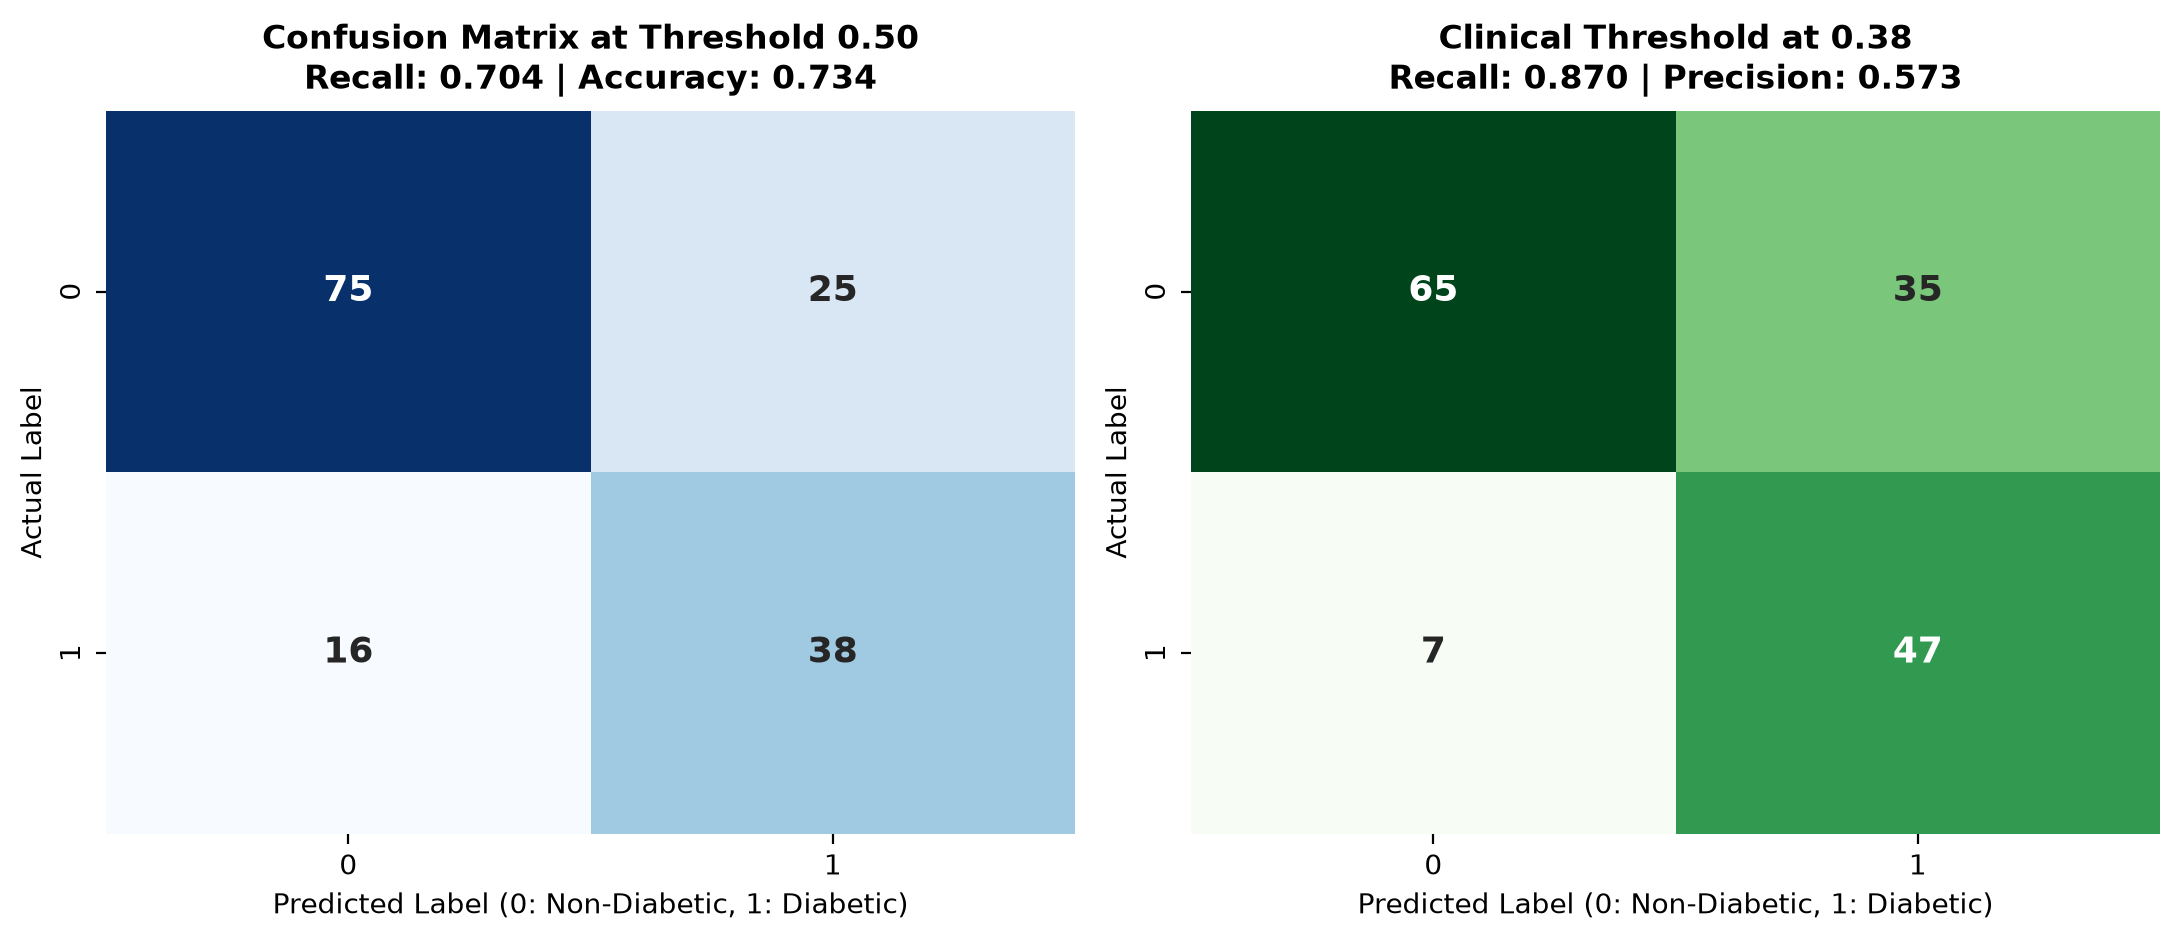

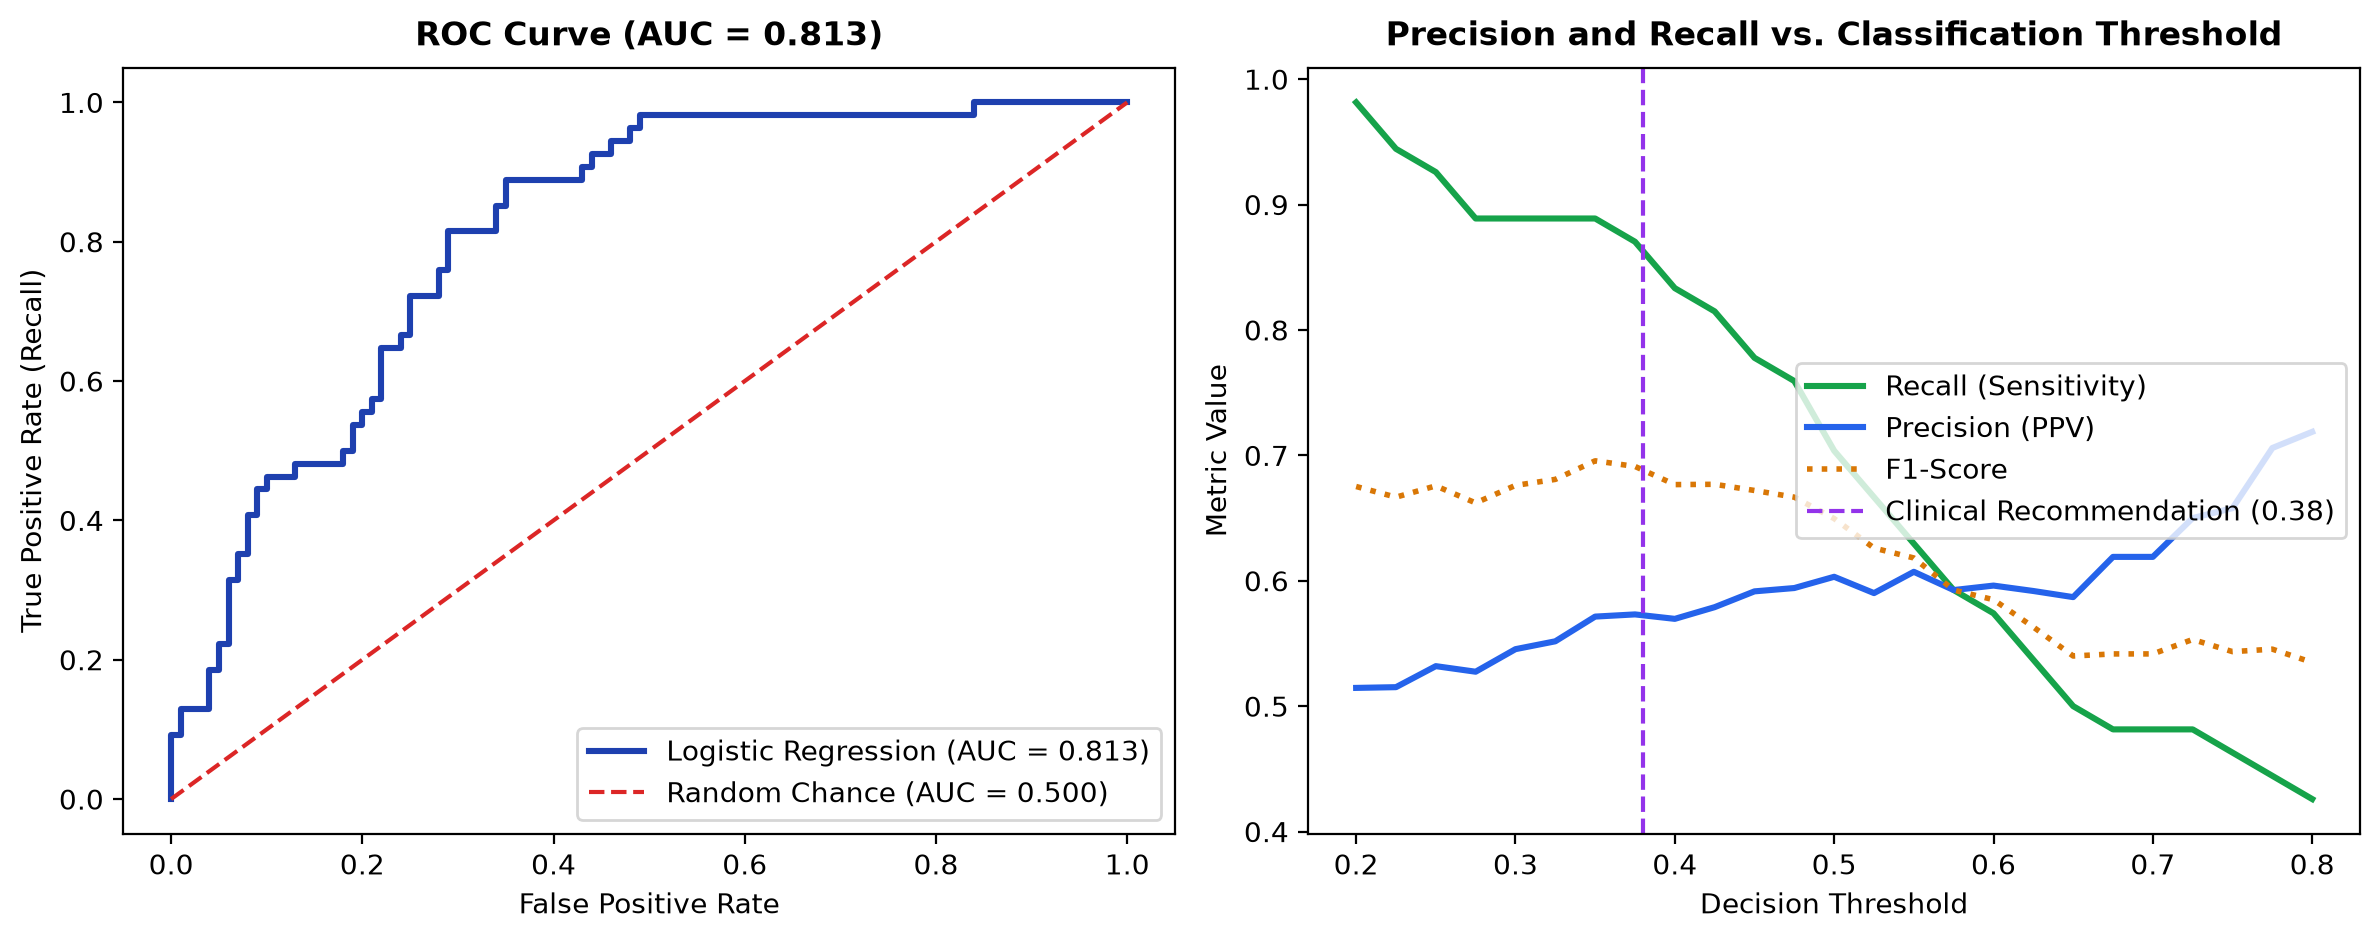

In [5]:
# Display generated comparative figures
from IPython.display import Image, display
display(Image('charts/mp2_chart1_confusion_matrices.png'))
display(Image('charts/mp2_chart2_threshold_tradeoff.png'))

## Step 6: Conclusion in My Own Words

**1. Baseline Model Behavior:**
Using the real Pima Indians Diabetes dataset with median imputation on missing values, our balanced Logistic Regression achieves an accuracy of 73.4%, recall of 70.4%, precision of 60.3%, and an AUC of 0.813. The model exhibits strong discriminatory capability in distinguishing diabetic from non diabetic individuals based on Glucose, BMI, and Age.

**2. The Recall vs Precision Trade-Off:**
At the standard 0.50 cutoff, the model misses 16 diabetic patients (false negatives). In a screening environment, missing an undiagnosed patient carries severe health risks. By shifting the classification threshold from 0.50 to 0.38, our recall increases from 70.4% to 87.0%, cutting missed cases from 16 down to 7. While precision slightly decreases from 60.3% to 57.3%, the trade-off is clinically justified because confirmatory blood tests are routine and safe, making high sensitivity the correct priority for disease screening.